<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/ES16-higgs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**HIGGS ML**

importo il dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Load CSV
df = pd.read_csv("higgs.csv")


In [ ]:
# Drop non-feature columns
event_ids = df['EventId']
weights = df['Weight']
labels = df['Label'].map({'s': 1, 'b': 0})


X = df.drop(['EventId', 'Weight', 'Label'], axis=1)

DRIVEN FEATURES SELECTION

In [ ]:
'''
selected_features=[
    'DER_mass_MMC',
    'DER_mass_vis',
    'DER_mass_transverse_met_lep',
    'PRI_jet_num',
    'DER_deltaeta_jet_jet',
    'DER_mass_jet_jet',
    'DER_prodeta_jet_jet',
    'PRI_tau_pt',
    'PRI_lep_pt',
    'DER_deltar_tau_lep',
    'DER_met_phi_centrality',


]
'''
#X = df[selected_features].astype(dtype=np.float32)
print(X.shape)

(250000, 30)


splitting train-validation-test set

In [ ]:
from sklearn.model_selection import train_test_split

X_train_full, X_test, y_train_full, y_test = train_test_split( #train-val - test split
    X, labels, test_size=0.2, stratify=labels, random_state=42
)
X_tr, X_val, y_tr, y_val = train_test_split(    #train- val split
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=42
)

NEURAL NETWORK APPROACH

need data preprocessing

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=-999.0, strategy='median', add_indicator=True) #indicatore= true preserva le info sui missing data, mediana più robusta
X_tr = imputer.fit_transform(X_tr)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test) #sostituisco i valori missing con la mediana del set di features per nn preservando info sui valori (ad esempio mi interessa sapere dove non ci sono jet )


scaler = StandardScaler() #scaling separati per evitare di fare leaking di informazioni tra i set
X_tr = scaler.fit_transform(X_tr)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


In [ ]:
print(X_train_full.shape)

(200000, 30)


GOAL COMPLETENESS


In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras_tuner import HyperModel
from keras_tuner.tuners import RandomSearch
from keras_tuner.engine.hyperparameters import HyperParameters

def build_model(hp):  #creo il modello
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(X_tr.shape[1],))) #input

    # regolarizazzione ridge l2 (prior gaussiano su ordini di grandezza)
    l2_reg = hp.Float('l2_reg', 1e-6, 1e-2, sampling='log')

    for i in range(hp.Int('num_layers', 2, 5)): #hidden layers con numero di layers da ottimizzare
        model.add(keras.layers.Dense(
            units=hp.Int(f'units_{i}', min_value=32, max_value=256, step=32), #numero di neuroni per layer da ottimizzare
            activation='relu', #activation function, scelgo relu per evitare vanishing gradient durante la backpropagation.
            kernel_initializer='he_normal',
           kernel_regularizer=keras.regularizers.l2(l2_reg)
        ))
        model.add(keras.layers.Dropout(rate=hp.Float(f'dropout_{i}', 0.1, 0.3, step=0.1)))

    model.add(keras.layers.Dense( #ultimo layer
        1, activation='sigmoid',  #activation function sigmoide per stimare la posterior
        kernel_regularizer=keras.regularizers.l2(l2_reg)
    ))

    lr = hp.Float('learning_rate', 1e-4, 1e-2, sampling='log') #learning rate da ottimizzare
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy', #mle bernulli
        metrics=['accuracy', keras.metrics.AUC(curve='PR', num_thresholds=1000, name='pr_auc')] #metrica sul quale ottimizzare
    )
    return model



In [ ]:
import keras_tuner as kt

tuner = kt.RandomSearch(
    build_model,
    objective=kt.Objective('val_pr_auc', direction='max'),
    max_trials=30,
    executions_per_trial=1,
    directory='keras_tuner_dir',
    project_name='higgsml_keras_pr',
    overwrite=True
)
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_pr_auc',
    patience=6,
    mode='max',
    restore_best_weights=True
)

tuner.search(
    X_tr, y_tr,
    epochs=50,
    batch_size=1024,
    validation_data=(X_val, y_val),  # Split stratificato e scalato
    callbacks=[early_stop]
)

Trial 30 Complete [00h 01m 14s]
val_pr_auc: 0.8525672554969788

Best val_pr_auc So Far: 0.8563361763954163
Total elapsed time: 01h 01m 33s


In [ ]:
# best iperparametri
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Migliori iperparametri trovati:", best_hp.values)

#costruisco il modello con best iperparametri
best_model = tuner.hypermodel.build(best_hp)


early_stop_final = keras.callbacks.EarlyStopping(
    monitor='val_pr_auc',
    patience=8,
    mode='max',
    restore_best_weights=True
)

best_model.fit(
    X_tr, y_tr,
    epochs=60,
    batch_size=1024,
    validation_data=(X_val, y_val),
    callbacks=[early_stop_final],
    verbose=1
)

Migliori iperparametri trovati: {'l2_reg': 0.00045433580386570224, 'num_layers': 5, 'units_0': 224, 'dropout_0': 0.2, 'units_1': 256, 'dropout_1': 0.1, 'learning_rate': 0.0005007779298026367, 'units_2': 192, 'dropout_2': 0.1, 'units_3': 128, 'dropout_3': 0.1, 'units_4': 128, 'dropout_4': 0.1}
Epoch 1/60
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.7513 - loss: 1.2835 - pr_auc: 0.6753 - val_accuracy: 0.8174 - val_loss: 1.1031 - val_pr_auc: 0.8061
Epoch 2/60
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.8054 - loss: 1.0550 - pr_auc: 0.7800 - val_accuracy: 0.8284 - val_loss: 0.9474 - val_pr_auc: 0.8297
Epoch 3/60
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.8168 - loss: 0.9161 - pr_auc: 0.8027 - val_accuracy: 0.8323 - val_loss: 0.8347 - val_pr_auc: 0.8367
Epoch 4/60
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.8233 - loss: 0.8100 - pr_auc: 0.8151 - val_accuracy: 0.8356 - val_loss: 0.7464 - val_pr_auc: 0.8422
Epoch 5/60
157/157 ━━━━━━━━━━━━━━━━━━━

49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


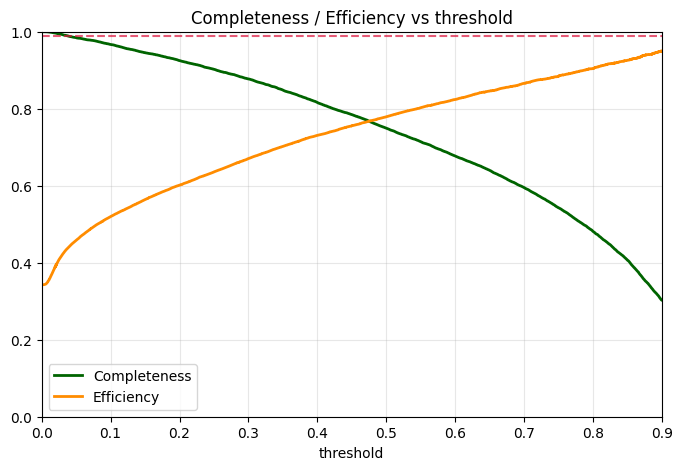


Per ottenere Completeness >= 99.0%:
-> Imposta soglia p_th = 0.0359
-> Efficiency risultante = 43.44% (Contamination = 56.56%)


In [ ]:
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score

y_prob_test = best_model.predict(X_test, batch_size=1024).ravel()

# Calcolo di Efficiency, Completeness
efficiency_tot, completeness_tot, thresholds_tot = precision_recall_curve(y_test, y_prob_test)
pr_auc = auc(completeness_tot, efficiency_tot)

#plot
fig,ax = plt.subplots(figsize=(8, 5))
#Completeness e Efficiency vs soglia
ax.plot(thresholds_tot, completeness_tot[:-1], lw=2, color='darkgreen', label='Completeness')
ax.plot(thresholds_tot, efficiency_tot[:-1], lw=2, color='darkorange', label='Efficiency')
ax.axhline(0.99, color='crimson', linestyle='--', alpha=0.7)
ax.set_xlabel('threshold')
ax.set_ylabel('')
ax.set_title('Completeness / Efficiency vs threshold')
ax.set_xlim([0.0, 0.9])
ax.set_ylim([0.0, 1.0])
ax.grid(True, alpha=0.3)
ax.legend(loc='best')

plt.show()


target_completeness = 0.99
# Trova la soglia più alta con completeness >= 99%
valid_idx_tot = np.where(completeness_tot[:-1] >= target_completeness)[0]
best_thresh_tot = thresholds_tot[valid_idx_tot[-1]]
eff_at_target_tot= efficiency_tot[valid_idx_tot[-1]]

print(f"\nPer ottenere Completeness >= {target_completeness:.1%}:")
print(f"-> Imposta soglia p_th = {best_thresh_tot:.4f}")
print(f"-> Efficiency risultante = {eff_at_target_tot:.2%} (Contamination = {1 - eff_at_target_tot:.2%})")

# Predizione con la soglia personalizzata (invece del default 0.5)
y_pred_custom_tot = (y_prob_test >= best_thresh_tot).astype(int)

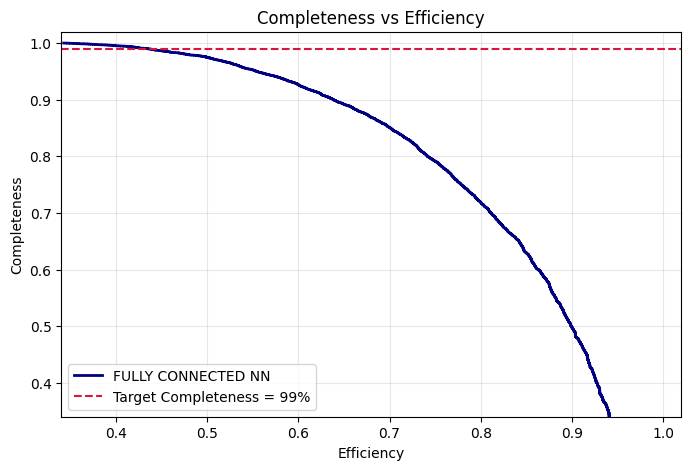

In [ ]:

fig, ax = plt.subplots(figsize=(8, 5))

# Completeness vs Efficiency
ax.plot(efficiency_tot, completeness_tot, lw=2, color='navy', label=f'FULLY CONNECTED NN')
ax.axhline(0.99, color='crimson', linestyle='--', label='Target Completeness = 99%')
ax.set_xlabel('Efficiency')
ax.set_ylabel('Completeness')
ax.set_title('Completeness vs Efficiency')
ax.set_xlim([0.34, 1.02])
ax.set_ylim([0.34, 1.02])
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left')

plt.show()


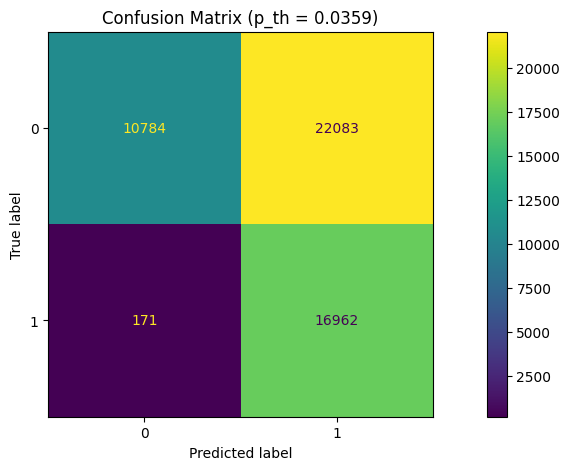

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_custom_tot,
    values_format='d',
    ax=ax
)
ax.set_title(f'Confusion Matrix (p_th = {best_thresh_tot:.4f})')

plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
p_test = best_model.predict(X_test, batch_size=1024).ravel()
print("ROC-AUC", roc_auc_score(y_test, p_test))
print("AP     ", average_precision_score(y_test, p_test))

X_tr_full = imputer.fit_transform(X_train_full)
X_tr_full = scaler.fit_transform(X_tr_full)
X_test_full = scaler.transform(X_test)

#confronto con histgradientboosting classifier
from sklearn.ensemble import HistGradientBoostingClassifier

gb = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05,
                                    early_stopping=True, random_state=42)
gb.fit(X_tr_full, y_train_full)
print("GBDT ROC-AUC", roc_auc_score(y_test, gb.predict_proba(X_test)[:,1]))

49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
ROC-AUC 0.910750017326534
AP      0.8521665193344471
GBDT ROC-AUC 0.9091461406395734


In [ ]:
print("AP", average_precision_score(y_test,gb.predict_proba(X_test)[:,1]))


AP 0.8497638191395042
